# 05 - Modelo baseline (avance de la fase de Resultados)

## 1. Configuración y carga

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

frames = pd.read_csv("../data/processed/frame_metrics.csv")
frames.head()


,brillo,contraste,saturacion,green_ratio,edge_density,video_id,time_s,label,path
0,85.351215,41.178807,119.844809,0.431215,0.191493,1606b0e6_0,0.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...
1,87.101233,40.901044,120.799722,0.435712,0.190660,1606b0e6_0,10.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...
2,87.284063,40.824245,120.699427,0.436128,0.190226,1606b0e6_0,20.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...
3,86.836181,40.478749,121.312014,0.440312,0.189045,1606b0e6_0,30.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...
4,88.082257,41.100076,120.895573,0.441528,0.190347,1606b0e6_0,40.0,bg,data/processed/frames/1606b0e6_0/1606b0e6_0__t...


## 2. Variable objetivo

El label incluye una cuarta clase, `bg` (frames de fondo muestreados de forma regular, no
asociados a un evento anotado). La mantenemos: en la práctica, un clasificador real también
necesita reconocer "aquí no está pasando nada de interés", no solo distinguir entre los tres
eventos.

In [ ]:
print(frames["label"].value_counts())
print()
print((frames["label"].value_counts(normalize=True) * 100).round(1))

label
play         7142
challenge    1051
bg            657
throwin       283
Name: count, dtype: int64

label
play         78.2
challenge    11.5
bg            7.2
throwin       3.1
Name: proportion, dtype: float64


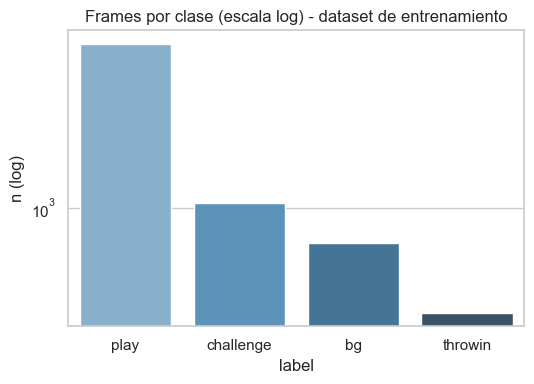

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 4))
order = frames["label"].value_counts().index
sns.barplot(x=order, y=frames["label"].value_counts().values, hue=order,
            palette="Blues_d", legend=False, ax=ax)
ax.set_yscale("log")
ax.set_title("Frames por clase (escala log) - dataset de entrenamiento")
ax.set_ylabel("n (log)")
plt.tight_layout()
plt.show()

## 3. División train/test por video

Dividir de forma aleatoria por fila filtraría información: frames del mismo partido y muy
cercanos en el tiempo terminarían tanto en train como en test, y el modelo podría "memorizar"
el partido en vez de aprender a distinguir eventos. Por eso se divide por `video_id`, dejando
partidos completos fuera del entrenamiento.

In [ ]:
FEATURES = ["brillo", "contraste", "saturacion", "green_ratio", "edge_density"]

X = frames[FEATURES]
y = frames["label"]
groups = frames["video_id"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train: {len(X_train)} frames de {frames.iloc[train_idx]['video_id'].nunique()} videos")
print(f"Test : {len(X_test)} frames de {frames.iloc[test_idx]['video_id'].nunique()} videos")
print()
print("Distribución de clases en train:")
print(y_train.value_counts(normalize=True).round(3))
print()
print("Distribución de clases en test:")
print(y_test.value_counts(normalize=True).round(3))

Train: 6422 frames de 2 videos
Test : 2711 frames de 1 videos

Distribución de clases en train:
label
play         0.802
challenge    0.103
bg           0.071
throwin      0.024
Name: proportion, dtype: float64

Distribución de clases en test:
label
play         0.734
challenge    0.144
bg           0.075
throwin      0.047
Name: proportion, dtype: float64


## 4. Modelo de referencia ("tonto" a propósito)

Antes de entrenar nada, establecemos qué tan bien le iría a un modelo que no aprende nada,
solo predice siempre la clase mayoritaria. Esto es exactamente el punto que se discutió en el
planteamiento del problema: con este desbalance, el accuracy solo no dice nada.

In [5]:
dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print(f"Accuracy del modelo 'tonto' (siempre predice la clase mayoritaria): {dummy.score(X_test, y_test):.1%}")
print(f"F1 macro (promedio simple entre clases): {f1_score(y_test, dummy_pred, average='macro'):.3f}")


Accuracy del modelo 'tonto' (siempre predice la clase mayoritaria): 73.4%
F1 macro (promedio simple entre clases): 0.212


El accuracy del modelo tonto es alto (domina la clase `play`), pero su F1 macro es bajo porque ignora por completo las clases minoritarias. Esta es la comparación base que cualquier modelo real debe superar, y no solo en accuracy.

## 5. Modelo baseline: Random Forest

In [6]:
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print(f"Accuracy: {rf.score(X_test, y_test):.1%}")
print(f"F1 macro: {f1_score(y_test, rf_pred, average='macro'):.3f}")
print()
print(classification_report(y_test, rf_pred, digits=3))


Accuracy: 65.2%
F1 macro: 0.219

              precision    recall  f1-score   support

          bg      0.058     0.098     0.073       204
   challenge      0.000     0.000     0.000       390
        play      0.738     0.878     0.802      1989
     throwin      0.000     0.000     0.000       128

    accuracy                          0.652      2711
   macro avg      0.199     0.244     0.219      2711
weighted avg      0.546     0.652     0.594      2711



C:\Users\isabe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\isabe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\isabe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_clas

## 6. Matriz de confusión

Muestra en qué se equivoca el modelo: qué clases confunde entre sí, no solo cuántas veces
acierta en total.

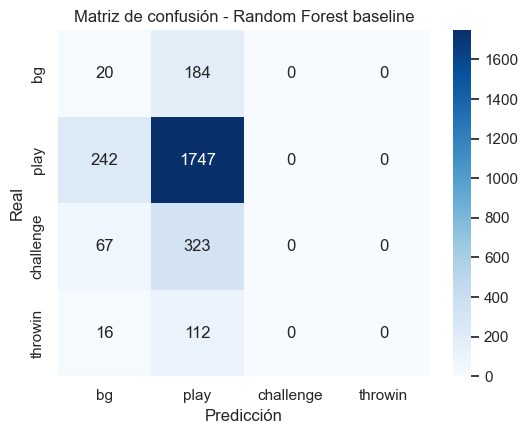

In [7]:
labels_order = ["bg", "play", "challenge", "throwin"]
cm = confusion_matrix(y_test, rf_pred, labels=labels_order)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión - Random Forest baseline")
plt.tight_layout()
plt.show()


## 7. Importancia de las variables

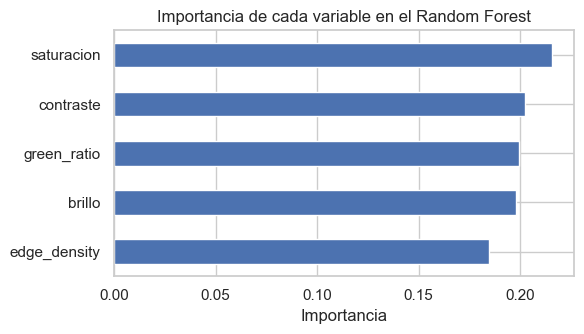

In [8]:
importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(6, 3.5))
importances.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Importancia de cada variable en el Random Forest")
ax.set_xlabel("Importancia")
plt.tight_layout()
plt.show()
